# 1. zárthelyi dolgozat, B) változat (2026. 05. 27.)

**Az első zárthelyi dolgozat során egy egyszerű Multi-layer Perceptron (MLP) típusú neuronhálót kell betanítani és kiértékelni egy multi-class klasszifikációs feladaton a PyTorch könyvtár segítségével.**

A zárthelyi több részfeladatból áll (A - H), melyek egymásra épülnek. A feladat automatikus tesztelőszkripttel rendelkezik és vizsgálja az egyes részfeladatokra adott megoldások helyességét. Éppen ezért, **ne változtasd meg a notebook struktúráját**, ne szedd több részre, illetve ne módosítsd a megírt részeket, csak a megoldásaidat írd be a megfelelő helyre, különben nem fogjuk tudni értékelni! A megoldások az `# Implement your solution BELOW` és `# Implement your solution ABOVE` sorok közé írandók. Ha a megoldott részfeladatok futtatásakor a "Tester: .... OK" felirat megjelenik, a tesztelőszkript nem talált hibát a megoldásban, azonban, a tesztelő nem teljeskörű, nem vesz észre mindenfajta hibát.

**A feladatban elérhető klasszifikációs pontosság:** Körülbelül 80-90% közti (kiegyensúlyozatlan, multi-class) accuracy érhető el a feladat helyes megoldásával. (A címke kategóriák nagyjából kiegyensúlyozottak lesznek.) Ha ennél jelentősen rosszabb, vagy jelentősen jobb az eredmény, amit a neuronháló legfeljebb elér a teszthalmazon, akkor hibára lehet gyanakodni és meg kell próbálni azt megtalálni: a részfeladatok eredményeit össze lehet például vetni a feladatok szövegével és az eredeti, szöveges fájlban letöltött adatbázisokkal.

**A megoldott feladatsor beadása:** Csak a kész megoldást tartalmazó notebookot (.ipynb) fájlként kell feltölteni a Canvas-ban, az 1. zárthelyi dolgozat beadási felületén, más fájlokat nem.
**Kérjük a notebook szerkezetét nem módosítani és nem szétszedni külön feladatok szerint!**

**Rendelkezésre álló idő:** 150 perc

**Értékelés:** Legfeljebb 45 pont gyűjthető: lásd a részfeladatokra adható pontokat az egyes feladatoknál. Minimum 22 pontot el kell érni ezen a zárthelyin a tárgy teljesítéséhez.

**Kikötés:** Ahol csak lehet, hatékony, vektorizált megoldásokat várunk. Nagy számú iterációt (50+) végrehajtó ciklus és hasonló, nem hatékony konstrukció a kódban pontlevonást eredményezhet. Kivételek, ahol büntetés nélkül használható hosszabb ciklus:
- Az A) feladatban.
- A háló betanításánál és az utolsó feladatban a tanítási/validációs/teszt loopban, akár epoch-ok, akár batch-ek iterálására.

---

Tesztelő szkript letöltése, importok.

In [ ]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

from WineQuality_MLP_Tester import Tester

## **A**: Az adatbázis betöltése - 2 pont

**Információ az adatbázisról**:
Az adatbázis az UCI Machine Learning Repository "Wine quality" adatbázisa alapján készült. Az adatbázis különböző fehérborok kémiai tulajdonságait tartalmazza (első tizenegy oszlop), valamint öt borszakértő, szubjektív, kóstolás alapján adott értékelését (0-10) a borokra (a maradék öt oszlop, a végén). Egy-egy sorban egy-egy fajta bor adatai találhatók meg.
A zárthelyi dolgozat keretében, **minőségbeli kategóriákat határozunk meg ("alsó polcos"/"középső polcos"/"felső polcos" borok), besoroljuk minden borunkat a három kategória egyikébe a borszakértők pontszámai alapján, majd ezt a kategóriacímkét tanuljuk meg megbecsülni a borok kémiai tulajdonságai alapján egy neuronhálóval.**

A tesztelőszkript letölti a szöveges formában tárolt adatbázist és elhelyezi a `content` sztringben. Alább, kiírjuk a hosszát és az első 500 karaktert is a sztringből. Az adatbázis fájlok egy-egy sora adja meg az egy-egy mintaelemhez tartozó változók értékeit. A sorokban az egyes változókhoz tartozó értékek vesszővel vannak elválasztva. Az adatbázis első sora a változók neveit tartalmazza.

In [2]:
tester = Tester()
content = tester.get_dataset_content()

print("Number of characters in dataset:", len(content))
print(content[:500])


Number of characters in dataset: 303452
"fixed acidity";"volatile acidity";"citric acid";"residual sugar";"chlorides";"free sulfur dioxide";"total sulfur dioxide";"density";"pH";"sulphates";"alcohol";"score1";"score2";"score3";"score4";"score5"
7;0.27;0.36;4.25;0.045;45;170;1.001;3;0.45;8.8;6;8;8;6;5
6.3;0.3;0.34;3.78;0.049;14;132;0.994;3.3;0.49;9.5;5;5;7;8;6
8.1;0.28;0.4;3.01;0.05;30;97;0.9951;3.26;0.44;10.1;6;7;6;5;6
0;0.23;0.32;3.82;0.058;47;186;0.9956;3.19;0.4;9.9;5;8;6;5;6
7.2;0.23;0.32;3.63;0.058;47;186;0.9956;3.19;0.4;9.9;6;7;4


A feladatod, hogy **alakítsd át a `content` sztringet az adatbázis változóinak értékeit tartalmazó NumPy tömbbé.** A tömbök adattípusa np.float32 (lebegőpontos) legyen! A változók értékeit helyezd el a `dataset_noisy` (n_mintaelem, n_változó) alakú tömbben!  Az input változókat és címkéket később választjuk majd szét.

Az adatbázis helyenként hiányzó értékeket tartalmaz: az adatok egy része nem volt elérhető az adatbázis rögzítésekor. Konkrétabban, a borok savasságára vonatkozó méréseket tartalmazó oszlopokban találhatók hiányzó értékek. Ezek a #0 ("fixed acidity") és #1 ("volatile acidity") indexű oszlopokban találhatók. A hiányzó értékek nullákkal (`0`) vannak helyettesítve. Ebben a részfeladatban ezekkel az értékekkel még nem kell külön foglalkoznod, 0 értékű számokként beolvashatod őket, a többi értékkel együtt.

In [17]:
# implement your solution BELOW


dataset = []

lines = content.strip().split('\n')
lines_segmented = [line.split(';') for line in lines]
data = lines_segmented[1:]


for rec in data:
  data_row=[]
  for d in rec:
    d = d.strip()
    val = float('nan') if d == '' else float(d)
    data_row.append(val)
  dataset.append(data_row)

print(dataset[:5])
dataset_noisy = np.array(dataset, dtype=np.float32)
print(dataset_noisy[:5])



# implement your solution ABOVE

tester.test('dataset_load', dataset_noisy)

[[7.0, 0.27, 0.36, 4.25, 0.045, 45.0, 170.0, 1.001, 3.0, 0.45, 8.8, 6.0, 8.0, 8.0, 6.0, 5.0], [6.3, 0.3, 0.34, 3.78, 0.049, 14.0, 132.0, 0.994, 3.3, 0.49, 9.5, 5.0, 5.0, 7.0, 8.0, 6.0], [8.1, 0.28, 0.4, 3.01, 0.05, 30.0, 97.0, 0.9951, 3.26, 0.44, 10.1, 6.0, 7.0, 6.0, 5.0, 6.0], [0.0, 0.23, 0.32, 3.82, 0.058, 47.0, 186.0, 0.9956, 3.19, 0.4, 9.9, 5.0, 8.0, 6.0, 5.0, 6.0], [7.2, 0.23, 0.32, 3.63, 0.058, 47.0, 186.0, 0.9956, 3.19, 0.4, 9.9, 6.0, 7.0, 4.0, 7.0, 5.0]]
[[7.000e+00 2.700e-01 3.600e-01 4.250e+00 4.500e-02 4.500e+01 1.700e+02
  1.001e+00 3.000e+00 4.500e-01 8.800e+00 6.000e+00 8.000e+00 8.000e+00
  6.000e+00 5.000e+00]
 [6.300e+00 3.000e-01 3.400e-01 3.780e+00 4.900e-02 1.400e+01 1.320e+02
  9.940e-01 3.300e+00 4.900e-01 9.500e+00 5.000e+00 5.000e+00 7.000e+00
  8.000e+00 6.000e+00]
 [8.100e+00 2.800e-01 4.000e-01 3.010e+00 5.000e-02 3.000e+01 9.700e+01
  9.951e-01 3.260e+00 4.400e-01 1.010e+01 6.000e+00 7.000e+00 6.000e+00
  5.000e+00 6.000e+00]
 [0.000e+00 2.300e-01 3.200e-01 

## **B**: A hiányzó adat kezelése - legfeljebb 7 pont

A hiányzó értékek szerencsénkre számokkal vannak jelölve, így nem lenne feltételnül muszáj foglalkoznunk velük, azonban ha bennhagyjuk őket 0 értékekként a tömbben, a neuronhálónk úgy is értelmezheti ezeket, mintha a szóban forgó borok savassága pontosan nulla lenne, ami nyilvánvalóan nem igaz - a hálónk tehát torz következtetésekre juthat.

### **1. (könnyű) opció** - 0 pont

Ebben az opcióban nem kezeljük a hiányzó adatokat, azok 0 értékekként mennek tovább. Tehát, nem kell semmit változtatnod az adatbázison, csak add értékül a `dataset_noisy` tömböt a `dataset` nevű változónak!

### **2. (nehéz) opció** - 4 pont

**Hozz létre két újabb változót, melyek azt jelzik, hogy valódi érték található-e a #0, illetve #1 indexű változókban az adott mintaelemnél, vagy nem!** Valódi érték esetén az új változó kapjon 1 értéket, hiányzó (0) érték esetén pedig 0 értéket! Helyezd el az eredeti adatot és az új változókat a `dataset` tömbben: az új változók oszlopai kerüljenek megfelelő sorrendben az első kettő változót tartalmazó oszlop **után**!

Mivel a 16 változós adatbázisunk #0 és #1 indexű oszlopai (változói) tartalmazhatnak hiányzó értékeket, az új `dataset` tömbünk 18 változós lesz és a két új változó a #2, illetve #3 indexű oszlopokba kerül. Például tehát, a #2 indexű oszlopban egy adott sorba nullás érték kerül, ha a #0-ás oszlopban annál a sornál hiányzó (0) érték található, egyébként pedig 1-es érték kerül oda. Hasonlóan készítjük el a #3 indexű oszlopot az #1 indexű oszlop alapján.


In [18]:
# implement your solution BELOW

dataset_new = np.insert(dataset_noisy, 2, values=0., axis=1)
dataset_new[:,2] = np.where(dataset_new[:,0]==0, 0., 1.)

dataset_new = np.insert(dataset_new, 3, values=0., axis=1)
dataset_new[:,3] = np.where(dataset_new[:,1]==0, 0., 1.)


dataset = dataset_new


# implement your solution ABOVE

tester.test('dataset_fill_missing', dataset)

Tester: Dataset fill missing: Identified solution aiming for option#2/3...
Tester: Dataset fill missing: Option #2 or 3 OK


## **C**: Tanító-, validációs- és teszthalmaz szétválasztása - 3 pont

**Keverd meg véletlenszerűen a mintaelemeket** a `dataset` tömbben! Ezt általánosságban azért célszerű megtenni, mert az adatbázisban az elemek valamilyen tulajdonságaik alapján rendezve lehetnek. Megkeverés nélkül, a szétválasztott halmazokban jelentősen különbözne a címkék eloszlása.

Ezt követően **válaszd szét a megkevert tömböt tanító-, validációs- és teszthalmazra**! Kerüljön 600-600 mintaelem a validációs- és teszthalmazba és a maradék a tanítóhalmazba (a sorrend mindegy)! A tanító-, validációs- és teszthalmazokat tartalmazó három tömböt nevezd el `dataset_split_train`, `dataset_split_val`, `dataset_split_test`-nek, sorrendben!

In [20]:
# implement your solution BELOW

dataset_shuffled = np.random.permutation(dataset)

dataset_split_train = dataset_shuffled[1200:, :]
dataset_split_val = dataset_shuffled[:600,:]
dataset_split_test = dataset_shuffled[600:1200, :]



# implement your solution ABOVE

tester.test('dataset_split', dataset_split_train, dataset_split_val, dataset_split_test)

Tester: Dataset split OK


## **D**: Az adat-iterátorok létrehozása a multi-class klasszifikációs feladathoz - 8 pont

A neuronhálók gradiens módszeres betanítását a legtöbbször iterátorokkal valósítjuk meg, melyek bejárják az adatbázisunkat és előállítják a neuronhálók tanításához szükséges input és címke kötegeket.

**Állítsd elő** a `dataloader_cl_train`, `dataloader_cl_val`, `dataloader_cl_test` nevű **iterálható objektumokat (Iterable)**, melyek olyan iterátorokat képesek visszaadni, amik a C) részfeladatban elkészült tanító-, validációs- és teszthalmazokat tartalmazó tömböket járják be! A multi-class klasszifikációs feladatban input változókként az összes változót felhasználjuk az adatbázisban, kivéve az öt borszakértő által adott pontszámot (`score1`, `score2`, `score3`, `score4`, `score5` nevű, utolsó öt oszlop az adatbázisban). Címkeként három kategóriát definiálunk és ezekbe a kategóriákba az alábbiak alapján sorolunk be borokat az adatbázisból:

- **"Alsó polcos borok"** kategória, #0 kategóriaindex: Azok a borok, amelyeket legalább egy borszakértő 3-as, vagy kisebb pontszámmal értékelt.
- **"Felső polcos borok"** kategória, #2 kategóriaindex: Azok a borok, amelyekre semelyik borszakértő nem adott 6-osnál rosszabb pontszámot és egyben az öt borszakértő pontszámának átlaga legalább 7.

- **"Középső polcos borok"** kategória, #1 kategóriaindex: Azok a borok, melyek nem kerültek be se az alsó polcos, se a felső polcos borok közé.

A fentiek alapján az iterátorok két tenzort adnak vissza minden lépésben:
- Az előbbi, az adatbázis összes felhasznált változójának értékét tartalmazza a kategóriákba besorolt mintaelemekre `torch.float32` adattípusban. Alakja `(batch_size, 11)`, ha a B/1-es opciót oldottad meg és `(batch_size, 13)`, ha a B/2-es vagy B/3-as opciót csináltad meg.
- Utóbbi (a címkéket tartalmazó tenzor) a borok kategóriáját fogja tartalmazni (azaz 0, 1 vagy 2 értékeket, `torch.int64` adattípusban, kategóriacímkék formájában). A tenzor alakja `(batch_size,)` lesz. `batch_size` ezúttal is a kötegben elhelyezett mintaelemek számát adja meg, ez kézzel beállítandó.

Az iterátorok implementációja többféleképpen megoldható, de javasolt a `torch.utils.data` modul `Dataset` és `DataLoader` osztályait felhasználni, vagy szükség esetén származtatni őket.

Figyelj rá, hogy az iterátorok által visszaadott **kötegekben várhatóan vegyesen legyenek mintaelemek mindkét kategóriából!** (Egy lehetséges megoldás erre a véletlen keverés.)

**Vigyázz, az iterátorok által visszaadott tenzoroknak csak az alakját ellenőrzi a tesztelő szkript, a tartalmát nem!**

In [32]:
# implement your solution BELOW

class MultiClassificationDataset(Dataset):
  def __init__(self, input_split, labels_split):
    self.xs = torch.tensor(input_split, dtype=torch.float32)
    self.ys = torch.tensor(labels_split, dtype=torch.int64)

  def __len__(self):
    return self.xs.shape[0]

  def __getitem__(self, idx):
    return self.xs[idx], self.ys[idx]

inputs_train = dataset_split_train[:,:-5]
scores = dataset_split_train[:, -5:] 
labels_train = np.where(np.count_nonzero(scores <= 3, axis=1) >= 1, 0, np.where((np.mean(scores, axis=1) >= 7) & (np.amin(scores, axis=1) >= 6), 2, 1))

inputs_val = dataset_split_val[:,:-5]
scores = dataset_split_val[:, -5:] 
labels_val = np.where(np.count_nonzero(scores <= 3, axis=1) >= 1, 0, np.where((np.mean(scores, axis=1) >= 7) & (np.amin(scores, axis=1) >= 6), 2, 1))

inputs_test = dataset_split_test[:,:-5]
scores = dataset_split_test[:, -5:] 
labels_test = np.where(np.count_nonzero(scores <= 3, axis=1) >= 1, 0, np.where((np.mean(scores, axis=1) >= 7) & (np.amin(scores, axis=1) >= 6), 2, 1))

train_dataset = MultiClassificationDataset(inputs_train, labels_train)
val_dataset = MultiClassificationDataset(inputs_val, labels_val)
test_dataset = MultiClassificationDataset(inputs_test, labels_test)

dataloader_cl_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_cl_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_cl_test = DataLoader(test_dataset, batch_size=32, shuffle=False)






# implement your solution ABOVE

tester.test('cl_iter', dataloader_cl_train, dataloader_cl_val, dataloader_cl_test)

Tester: Dataset iterators for classification task OK


## **E**: A neuronháló definiálása - 4 pont

**Definiáld a multi-class klasszifikációs feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely az általános `torch.nn.Module` osztály leszármazottja, majd példányosítsd azt és add értékül a `multiclass_cl_model` nevű változónak a példányt!

A neuronháló **tartalmazzon 2 teljesen összekötött réteget**! Az **első rétegben** legyen 20 neuron és alkalmazz rajta ReLU aktivációs függvényt! A **második réteg** neuronjainak számát és aktivációs függvényét a végrehajtandó multi-class klasszifikációs feladat adja meg. Betanításkor nullázd ki a ReLU aktivációs függvény kimeneteként kapott vektorreprezentáció egyes elemeit 10% valószínűséggel! (Azaz, egy dropout "rétegre" lesz szükséged a ReLU után.)

Az új osztálynak mindenképpen meg kell valósítania a `forward(self, x)` tagfüggvényt, mely a neuronhálót (hipotézisfüggvényt) az `x` input tenzorra kiértékeli. A `forward` függvény fogja majd az előbb definiált adat-iterátorból érkező input tenzorokat megkapni és előállítani belőle a címkebecsléseket. Az osztály konstruktorában célszerű a neuronhálónk rétegeit inicializálni.

**Emlékeztető:** Figyelj oda rá, hogy a dropout csak betanítás közben működjön! (Előadáson volt róla szó.)

In [37]:
# implement your solution BELOW

class MultiClassifierModel(nn.Module):

  def __init__(self, input_dim):
        super().__init__()
        self.layers = nn.Sequential(   # option#1 put all layers/operations into a Sequential (nn.Module subclass type)
            nn.Linear(input_dim, 20),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(20, 3),
        )

  # Regression: no activation function at end
  # Binary classification: Sigmoid at end
  # Multi-class classification: no activation function at end ONLY IN PYTORCH (Softmax is included in CELoss)

  def forward(self, x):
      return self.layers(x)


multiclass_cl_model = MultiClassifierModel(input_dim=13)


# implement your solution ABOVE

tester.test('cl_model_architecture', multiclass_cl_model)

Tester: Classification model architecture OK


## **F**: A háló betanítása multi-class klasszifikációs feladatra - 7 pont

- **Tanítsd be a** `multiclass_cl_model` **neuronhálót** a tanítóhalmazon a `dataloader_cl_train` által visszaadott iterátorok segítségével és alkalmazd a `dataloader_cl_val` által visszaadott iterátorokat a validációhoz! Az iterátorok egyetlen (akár véletlen sorrendben történő) végighaladása a tanító és validációs adathalmazokon határoz meg egy _epoch_-ot.

  Alkalmazd a betanításhoz a multi-class klasszifikációkor szokásosan használt **költségfüggvényt**!

  A betanításhoz válassz egy gradiens módszer alapú **optimalizációs algoritmust** a `torch.optim` modulból (pl. `SGD`, `Adam`, `RMSprop`, stb.), majd válassz egy megfelelő **tanulási rátát** is!

- A tanítást az **early stopping** technika állítsa le! Amennyiben adott számú epoch-on keresztül (`patience`) nem javul a validációs költség, érjen véget a betanítás és **állítsuk vissza a `multiclass_cl_model` súlyait abból az epoch-ból, amikor a legjobb volt a validációs költség!** Mindez automatikusan történjen!

- **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonok kirajzolásához használhatod például a `matplotlib` könyvtárat. Figyelj rá, hogy a grafikonon jól látszódjanak a görbék közti eltérések a tanítás végén is! Ha szükséges, beállíthatod ehhez kézzel, hogy az y tengely melyik részét mutassa a grafikon.

  **A grafikonon legyen jelmagyarázat** (legend), mely megmutatja, melyik görbe írja le a tanítási költséget és melyik a validációs költséget!

- A betanítás végeztével **mérd le az átlagos költséget a teljes teszthalmazon** és add értékül a kapott számot a `test_ce` változónak!

- **Számold ki az _accuracy_ (pontosság) metrikát is a teszthalmaz elemein** és add értékül a kapott számot a `test_acc` változónak!! Az _accuracy_ metrika a helyesen klasszifikált mintaelemek arányát adja meg. Például, ha 150 mintaelem kategóriájának becslésekor 75 esetben találtuk el a helyes kategóriát, az _accuracy_ értéke 0.5 lesz. Figyelj oda, hogy a multi-class klasszifikációval kompatibilis módon számold ezt ki!

- **Válassz néhány mintaelemet a teszthalmazból** (például a `dataloader_cl_test` iterátor segítségével) és **adj becslést a címkéjükre** az input változók értékei alapján, majd **írasd ki az egyes mintaelemekre a becsült és az igazi címkéjüket kategóriák formájában** (Például: `Prediction: 2, true label: 1`)! Így példákon is láthatjuk, hogy mennyire ad jó becsléseket a neuronhálónk.



Epoch #0, tr loss: 0.4143364727497101, val loss: 0.3383205533027649, tr acc: 0.8406369686126709, val acc: 0.8651315569877625
    Early stopping: Best model updated.
Epoch #1, tr loss: 0.40222686529159546, val loss: 0.3369826674461365, tr acc: 0.8437200784683228, val acc: 0.8618420958518982
    Early stopping: Best model updated.
Epoch #2, tr loss: 0.4043961763381958, val loss: 0.3423486351966858, tr acc: 0.8412355780601501, val acc: 0.875
Epoch #3, tr loss: 0.4038763642311096, val loss: 0.328876793384552, tr acc: 0.8381525278091431, val acc: 0.862390398979187
    Early stopping: Best model updated.
Epoch #4, tr loss: 0.40263551473617554, val loss: 0.40521687269210815, tr acc: 0.8386912941932678, val acc: 0.8366227746009827
Epoch #5, tr loss: 0.3992618918418884, val loss: 0.3337644636631012, tr acc: 0.8331536650657654, val acc: 0.8744516968727112
Epoch #6, tr loss: 0.402466744184494, val loss: 0.32975324988365173, tr acc: 0.8425825834274292, val acc: 0.8760964274406433
Epoch #7, tr loss

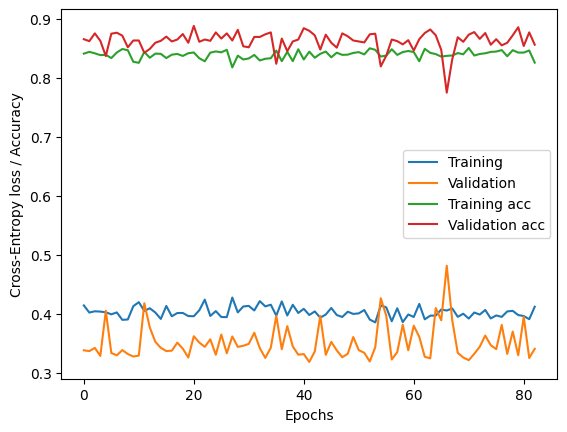

1 - Prediction: 2 | Real data: 2
2 - Prediction: 0 | Real data: 0
3 - Prediction: 1 | Real data: 1
4 - Prediction: 1 | Real data: 0
5 - Prediction: 0 | Real data: 0
Tester: Classification model learning OK


In [40]:
# implement your solution BELOW

inputs_train_t = torch.tensor(inputs_train, dtype=torch.float32)
inputs_val_t = torch.tensor(inputs_val, dtype=torch.float32)
inputs_test_t = torch.tensor(inputs_test, dtype=torch.float32)
labels_train_t = torch.tensor(labels_train, dtype=torch.long)
labels_val_t = torch.tensor(labels_val, dtype=torch.long)
labels_test_t = torch.tensor(labels_test, dtype=torch.long)

def multi_acc_fn(y_hat, y_true):
    preds = torch.argmax(y_hat, dim=1)
    return torch.count_nonzero(preds == y_true) / y_hat.shape[0]

loss_fn = nn.CrossEntropyLoss()

n_max_epochs = 150
learning_rate = 0.01
optimizer = torch.optim.Adam(multiclass_cl_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []
best_cl_model = None
best_val_loss = float('inf')
early_stopping_patience = 40
last_early_stopping_update_ep_idx = 0

for epoch_idx in range(n_max_epochs):

    # training
    multiclass_cl_model.train()
    train_losses_in_epoch = []
    train_accs_in_epoch = []

    for train_batch_xs, train_batch_ys in dataloader_cl_train:

        optimizer.zero_grad()
        train_batch_ys_pred = multiclass_cl_model(train_batch_xs)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)
        acc = multi_acc_fn(train_batch_ys_pred, train_batch_ys)

        train_losses_in_epoch.append(loss.detach())
        train_accs_in_epoch.append(acc)
        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    train_accs_in_epoch = torch.tensor(train_accs_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()
    avg_tr_epoch_acc = train_accs_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)
    train_accuracy.append(avg_tr_epoch_acc)

    multiclass_cl_model.eval()
    val_losses_in_epoch = []
    val_accs_in_epoch = []

    for val_batch_xs, val_batch_ys in dataloader_cl_val:

        with torch.no_grad():
            val_batch_ys_pred = multiclass_cl_model(val_batch_xs)
        loss = loss_fn(val_batch_ys_pred, val_batch_ys)
        acc = multi_acc_fn(val_batch_ys_pred, val_batch_ys)

        val_losses_in_epoch.append(loss)
        val_accs_in_epoch.append(acc)

    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    val_accs_in_epoch = torch.tensor(val_accs_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()
    avg_val_epoch_acc = val_accs_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)
    val_accuracy.append(avg_val_epoch_acc)

    # logging
    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

    # early stopping
    if avg_val_epoch_loss < best_val_loss:
        best_val_loss = avg_val_epoch_loss
        best_cl_model = copy.deepcopy(multiclass_cl_model)
        last_early_stopping_update_ep_idx = epoch_idx
        print("    Early stopping: Best model updated.")

    # early stopping: break if no update for a long time
    if last_early_stopping_update_ep_idx + early_stopping_patience < epoch_idx:
        print("Training is terminated by early stopping.")
        break

print("Training finished. Best model weights are restored.")
multiclass_cl_model = best_cl_model

test_ys_preds = []
for test_batch_xs, test_batch_ys in dataloader_cl_test:
    with torch.no_grad():
        test_batch_ys_pred = multiclass_cl_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)

test_ys_preds = torch.cat(test_ys_preds, dim=0)
test_ce = loss_fn(test_ys_preds, labels_test_t)
test_acc = multi_acc_fn(test_ys_preds, labels_test_t)

print(f"Test loss: {test_ce}, test acc: {test_acc}")

plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('Cross-Entropy loss / Accuracy')
plt.legend()
plt.show()

predicted_classes = torch.argmax(test_ys_preds, dim=1)
for i in range(5):
    prediction = predicted_classes[i].item()
    real = labels_test_t[i].item()
    print(f"{i+1} - Prediction: {prediction} | Real data: {real}")


# implement your solution ABOVE

tester.test('cl_model_learning', test_ce, test_acc)

## **G**: Hisztogram - 4 pont

Ebben a feladatban azt vizsgáljuk, hogy mennyire különbözik az alsó-, középső- és felső polcos borok cukortartalma. Az alábbihoz hasonló grafikont kell elkészítened:

<br>
<img src="./zh_files/zh1b_hist.png" style="display:inline-block" width='60%'>
<hr>

Válaszd külön a teszthalmaz mintaelemeit azok igazi címkekategóriája szerint, majd rajzold ki kategóriánként az odatartozó mintaelemek hisztogramját a cukortartalom ("residual sugar") változó értéke szerint! Ez a változó a #3-as indexű oszlopban található, ha a B/1-es opciót oldottad meg, egyébként pedig az #5-ös indexű oszlopban. A hisztogramban a mintaelemeket kosarakba (bins) csoportosítjuk a cukortartalom értéke (vízszintes tengely) szerint. Az egyes kosarakban található elemek számát a függőleges tengely hosszában elhelyezkedő oszlopok adják meg.

A hisztogramok elkészítéséhez javasolt (de nem kötelező) a `matplotlib.pyplot.hist()` függvény használata.







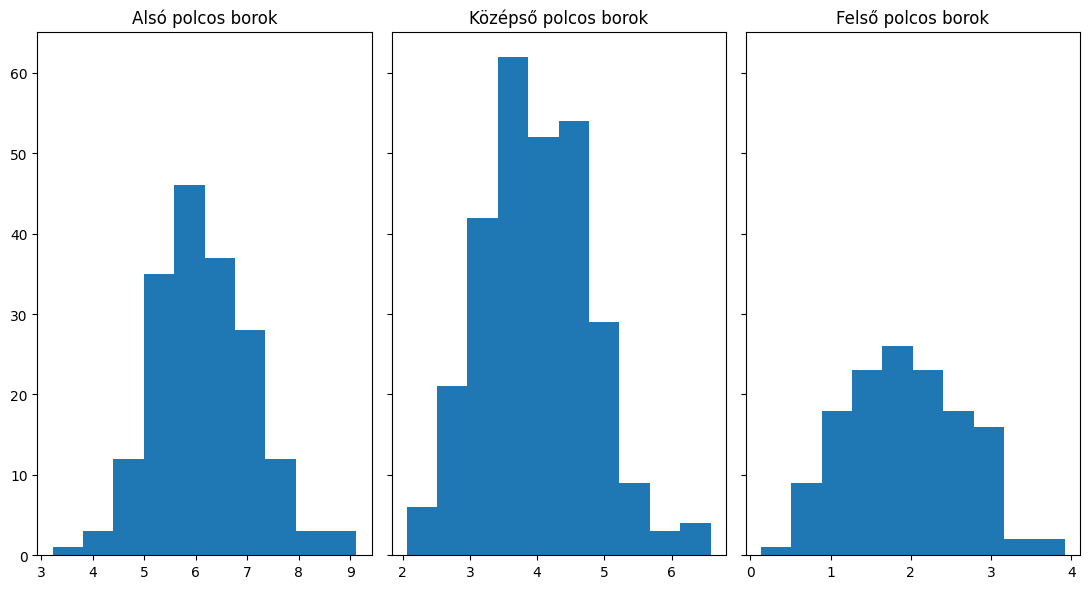

In [47]:
# implement your solution BELOW (No automatic tests for this task)

dataset_also = dataset_split_test[labels_test==0,:]
dataset_kozepso = dataset_split_test[labels_test==1,:]
dataset_felso = dataset_split_test[labels_test==2,:]

fig, axs = plt.subplots(nrows=1, ncols=3, sharey=True, tight_layout=True, figsize=(11,6))
axs[0].hist(dataset_also[:,5])
axs[0].set_title("Alsó polcos borok")
axs[1].hist(dataset_kozepso[:,5])
axs[1].set_title("Középső polcos borok")
axs[2].hist(dataset_felso[:,5])
axs[2].set_title("Felső polcos borok")
plt.show()




## **H**: Makro-átlagolt pontosság (macro-averaged accuracy) metrika - 6 + 4 pont

**!!! A feladat megoldásához csak Python beépített függvényeket/szerkezeteket, illetve Numpy-t és PyTorch-ot használhatsz (Scikit-learn és más csomagok nem használhatók itt) !!!**

A hagyományos pontosság (accuracy) metrika nem képes kezelni a kiegyensúlyozatlan adatbázisokat: ha péládul, a mintaelemeink 80 százaléka az 1-es kategóriába tartozik és a modellünk mindössze annyit tanul meg, hogy minden esetben, függetlenül az inputtól, becsülje az 1-es kategóriacímkét, akkor a modellünk 80%-os pontosságot ér el, miközben semmilyen értékes tudása nincsen. Az alábbiakban a pontosság metrika egy kiegyensúlyozott változatát kell implementálnod kettőnél több kategóriás (multi-class) esetekre.

Számolásához a bináris (két kategóriás) esetből indulhatunk ki. Két kategória esetén az egyik, választott kategóriát pozitív kategóriának nevezzük el, míg a másik lesz a negatív kategória. A bináris pontosság (binary accuracy) metrika így a következő:

$$ Binary\ accuracy = \dfrac{VP + VN}{VP + VN + FP + FN} = \dfrac{VP + VN}{\text{a mintaelemek száma}}$$

ahol VP a valós pozitívok száma (azaz, ahol a pozitív kategóriát helyesen becsültük), VN a valós negatívok száma (azaz, ahol a negatív kategóriát helyesen becsültük), FP a fals pozitívok száma (ahol helytelenül a pozitív kategóriába soroltuk a mintaelemet), FN pedig a fals negatívok száma (ahol helytelenül a negatív kategóriába soroltuk a mintaelemet). A számláló tehát egyenlő a bináris feladatban helyesen klasszifikált elemek számával, maga a hányados pedig a bináris feladatban helyesen klasszifikált elemek arányával.

Mivel most három kategóriánk van, ki kell terjesztenünk a fenti metrikát a multi-class kalsszifikáció esetére is. Ekkor a fenti hányadost háromszor számoljuk ki függetlenül a három kategóriánkra úgy, hogy mindegyik esetben a kiválasztott kategóriánk lesz a pozitív kategória és az összes másik kategória együttesen alkotja a negatív kategóriát. **A makro-átlagolt pontosságot (macro-averaged accuracy) a három kategóriához számolt bináris pontosság értékek átlaga fogja megadni.**

### **Alapfeladat**: 6 pont

**Számold ki a neuronháló által a teszthalmaz elemein elért makro-átlagolt pontosság (macro-averaged accuracy) metrikát!** A különböző kategóriák felsorolására alkalmazhatsz ciklust, de az adatpontok feletti iterálásért pontlevonás jár. A számolásod helyességét a lejjebb található kis méretű példával tesztelheted.

**!!! A feladat megoldásához csak Python beépített függvényeket/szerkezeteket, illetve Numpy-t és PyTorch-ot használhatsz (Scikit-learn és más csomagok nem használhatók itt) !!!**

(Olvasd el a megoldás megkezdése előtt a következő opciót is!)

### **Opcionális feladat**: további +4 pont

Valósítsd meg a fent leírt feladatot, azonban oldd meg azt teljesen vektorizált módon: kategóriák felsorolására se használj ciklust, vagy hasonló, nem hatékony konstrukciókat!

---

_**Példa a makro-átlagolt pontosság metrika számolására:**_

Öt mintaelemünk van, melyeket három kategória egyikébe sorolunk.

Igazi címkéik: [0, 2, 1, 1, 1]

A neuronhálónk által a legnagyobb valószínűséggel becsült címkéik: [0, 0, 2, 2, 1]

Ekkor a makro-átlagolt pontosság metrikát az alábbi módon számoljuk:
- #0 kategória: egy darab pozitív (#0 kategóriájú) mintaelemünk van és ezt helyesen klasszifikáltuk (VP = 1), négy darab negatív (nem #0 kategóriájú) mintaelemünk van és ebből hármat sikerült helyesen a negatív kategóriába sorolni (VN = 3). Összesen öt mintaelemünk van, így (1+3)/5 = 4/5 a bináris pontosság.
- #1 kategória: három darab pozitív (#1 kategóriájú) mintaelemünk van és ebből egyet klasszifikáltuk helyesen (VP = 1), két darab negatív (nem #1 kategóriájú) mintaelemünk van és mindkettőt sikerült helyesen a negatív kategóriába sorolni (VN = 2). Összesen öt mintaelemünk van, így (1+2)/5 = 3/5 a bináris pontosság.
- #2 kategória: egy darab pozitív (#2 kategóriájú) mintaelemünk van és ezt nem klasszifikáltuk helyesen (VP = 0), négy darab negatív (nem #2 kategóriájú) mintaelemünk van és ebből csak kettőt sikerült helyesen a negatív kategóriába sorolni (VN = 2). Összesen öt mintaelemünk van, így (0+2)/5 = 2/5 a bináris pontosság.

A makro-átlagolt pontosság a három szám átlaga lesz: (4/5 + 3/5 + 2/5)/3 = 3/5 = 0.6

In [ ]:
TEST_CASE_TRUE = [0, 2, 1, 1, 1]            # ->
TEST_CASE_PREDS = [0, 0, 2, 2, 1]           # -> result on these should be exactly 0.6

# implement your solution BELOW (No automatic tests for this task)








